# Modulación_FSK — Laboratorio 6 COEL (Modulaciones digitales)
Escuela Colombiana de Ingeniería Julio Garavito · Ingeniería Electrónica

**Integrantes:** _(completar)_ · **Fecha:** _(completar)_ · **Técnica asignada al grupo:** FSK

Este cuaderno sigue la *Parte 2* de la guía (pasos 1–10). Cada celda lleva comentarios línea a línea.
Donde la guía tenía errores de ejecución se corrigió y se dejó la nota **[CORRECCIÓN]** (ver `docs/00_revision_guia.md`).

## Paso 2 · Librerías

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import scipy
import wave

# Carpeta donde se guardan las figuras (solo si se ejecuta dentro del repositorio; en Colab se omite)
FIG_DIR = "../figures" if os.path.isdir("../figures") else None
def guardar(nombre):
    """Guarda la figura activa como PNG en figures/ (para el informe)."""
    if FIG_DIR:
        plt.savefig(f"{FIG_DIR}/{nombre}.png", dpi=150, bbox_inches="tight")

np.random.seed(42)  # semilla fija: resultados reproducibles para el informe
print("numpy", np.__version__, "| scipy", scipy.__version__)

numpy 2.5.4 | scipy 1.18.1


## Pasos 3–4 · Constelación QPSK (referencia) y ruido AWGN
Los símbolos QPSK están a 45°, 135°, 225° y 315° sobre el círculo unitario.
`x_int ∈ {0,1,2,3}` → grados = `x_int·90 + 45` → radianes → símbolo complejo `cos θ + j sin θ`.

> **[CORRECCIÓN]** En la guía los ejes están rotulados "Sin(wc·t)" en X y "Cos(wc·t)" en Y; X es la componente en fase (I, `cos`) y Y la de cuadratura (Q, `sin`). Aquí se rotulan I y Q.

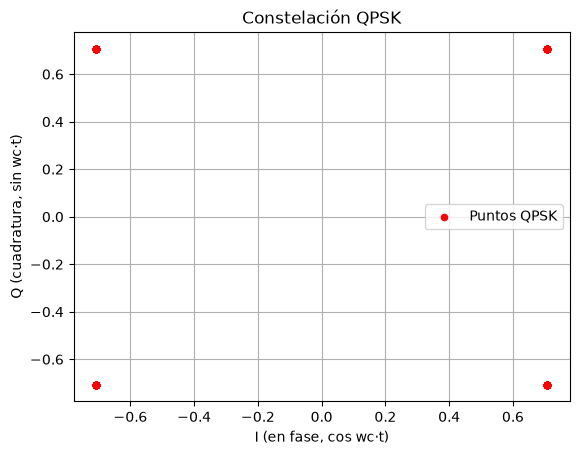

In [2]:
num_symbols = 1000                                   # Número de símbolos
x_int = np.random.randint(0, 4, num_symbols)         # Enteros aleatorios en {0,1,2,3} (el límite superior 4 es exclusivo)
x_degrees = x_int*360/4.0 + 45                       # Símbolo -> grados: 45, 135, 225, 315
x_radians = x_degrees*np.pi/180.0                    # Grados -> radianes
x_symbols = np.cos(x_radians) + 1j*np.sin(x_radians) # Símbolos complejos QPSK

plt.scatter(np.real(x_symbols), np.imag(x_symbols), s=20, c='red', label="Puntos QPSK")
plt.title("Constelación QPSK")
plt.xlabel("I (en fase, cos wc·t)")
plt.ylabel("Q (cuadratura, sin wc·t)")
plt.grid(True); plt.legend(); guardar("fsk_01_qpsk_sin_ruido"); plt.show()

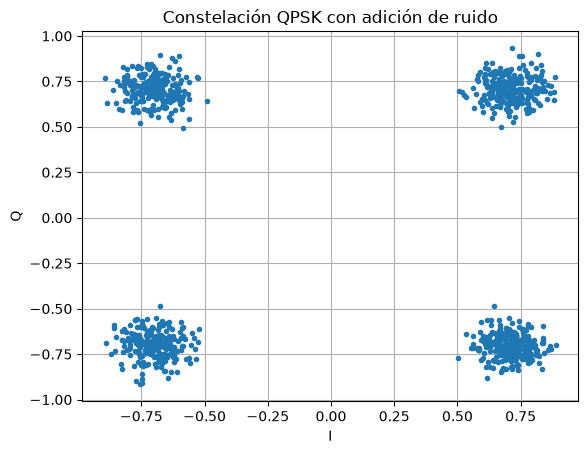

In [3]:
# Ruido blanco gaussiano complejo de potencia unitaria: (N(0,1) + jN(0,1))/sqrt(2)
n = (np.random.randn(num_symbols) + 1j*np.random.randn(num_symbols))/np.sqrt(2)
noise_power = 0.01                                   # Potencia del ruido (relación señal/ruido = 1/0.01 = 20 dB)
r = x_symbols + n*np.sqrt(noise_power)               # Símbolos + AWGN

plt.title("Constelación QPSK con adición de ruido")
plt.xlabel("I"); plt.ylabel("Q")
plt.plot(np.real(r), np.imag(r), '.')
plt.grid(True); guardar("fsk_02_qpsk_awgn"); plt.show()

## Paso 5 · Aumentar el ruido hasta provocar errores de decisión y ruido de fase
Se barre `noise_power` y se cuenta la tasa de error de símbolo (SER) decidiendo por cuadrante (el receptor ideal de QPSK).

noise_power = 0.01  -> SER = 0.0000
noise_power = 0.1   -> SER = 0.0013
noise_power = 0.5   -> SER = 0.1504
noise_power = 1     -> SER = 0.2969
noise_power = 2     -> SER = 0.4197


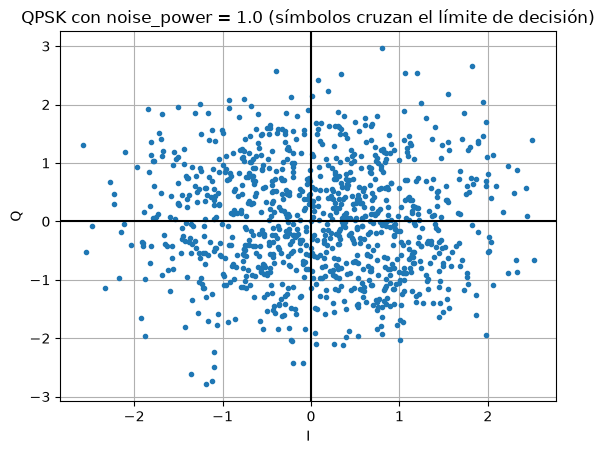

In [4]:
def ser_qpsk(noise_power, N=20000):
    """Tasa de error de símbolo de QPSK con decisión por cuadrante."""
    xi = np.random.randint(0, 4, N)
    s = np.exp(1j*(xi*np.pi/2 + np.pi/4))
    w = (np.random.randn(N) + 1j*np.random.randn(N))/np.sqrt(2)
    rr = s + w*np.sqrt(noise_power)
    # Decisión: el símbolo estimado es el punto de la constelación en el mismo cuadrante que rr
    est = (np.sign(rr.real) + 1j*np.sign(rr.imag))/np.sqrt(2)
    return np.mean(np.abs(est - s) > 1e-9)

for p in [0.01, 0.1, 0.5, 1, 2]:
    print(f"noise_power = {p:<5} -> SER = {ser_qpsk(p):.4f}")

# Constelación con ruido alto (los puntos cruzan los límites de cuadrante)
r_alto = x_symbols + n*np.sqrt(1.0)
plt.plot(np.real(r_alto), np.imag(r_alto), '.')
plt.axhline(0, c='k'); plt.axvline(0, c='k')
plt.title("QPSK con noise_power = 1.0 (símbolos cruzan el límite de decisión)")
plt.xlabel("I"); plt.ylabel("Q"); plt.grid(True); guardar("fsk_03_qpsk_ruido_alto"); plt.show()

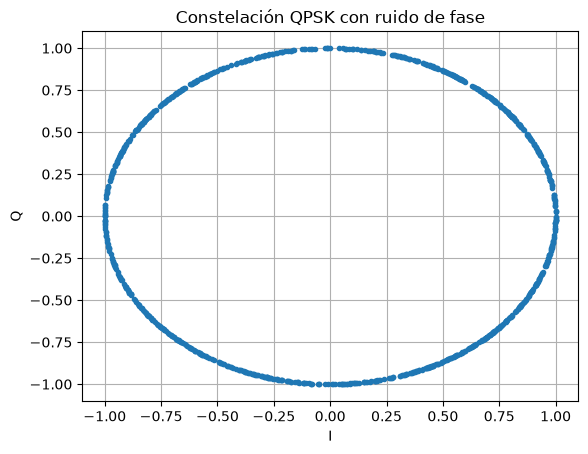

In [5]:
# Ruido de fase (jitter del oscilador local): rotación aleatoria de cada símbolo
phase_noise = np.random.randn(len(x_symbols))*0.5    # desviación estándar 0.5 rad
r = x_symbols*np.exp(1j*phase_noise)                 # Símbolos con ruido de fase

plt.title("Constelación QPSK con ruido de fase")
plt.xlabel("I"); plt.ylabel("Q")
plt.plot(np.real(r), np.imag(r), '.')
plt.grid(True); guardar("fsk_04_qpsk_ruido_fase"); plt.show()

## Paso 6 · AWGN y ruido de fase simultáneos

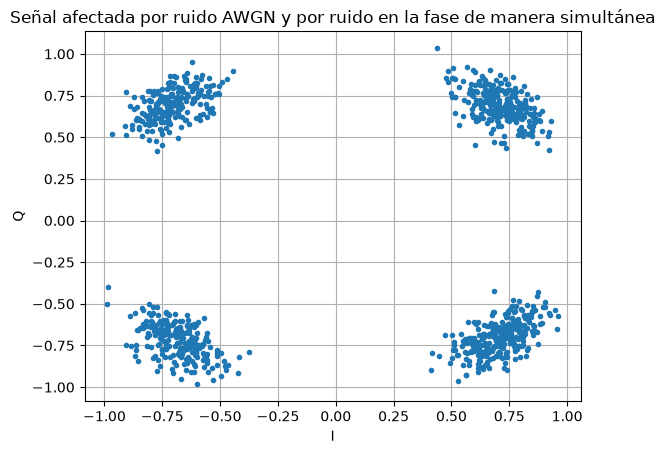

In [6]:
n = (np.random.randn(num_symbols) + 1j*np.random.randn(num_symbols))/np.sqrt(2)  # AWGN complejo, potencia unitaria
noise_power = 0.01                                    # Potencia de ruido AWGN
phase_noise = np.random.randn(len(x_symbols))*0.1     # Ruido de fase (desv. 0.1 rad) – su factor regula la "intensidad"
r = (x_symbols*np.exp(1j*phase_noise)) + n*np.sqrt(noise_power)  # Rotación de fase + ruido aditivo

plt.plot(np.real(r), np.imag(r), '.')                 # Gráfico de dispersión
plt.title("Señal afectada por ruido AWGN y por ruido en la fase de manera simultánea")
plt.xlabel("I"); plt.ylabel("Q"); plt.grid(True); guardar("fsk_05_qpsk_awgn_fase"); plt.show()

## Paso 7 · FSK: duplicar la frecuencia con `sin(2x) = 2·sin(x)·cos(x)`
Multiplicar `sin(x)` por `2cos(x)` produce una senoide de frecuencia doble (la guía usa 4 Hz → 8 Hz).

In [7]:
def setup_graph(title='', x_label='', y_label='', fig_size=None):
    """Crea una figura con título, etiquetas y tamaño opcional (misma función de la guía)."""
    fig = plt.figure()
    if fig_size is not None:
        fig.set_size_inches(fig_size[0], fig_size[1])
    ax = fig.add_subplot(111)
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

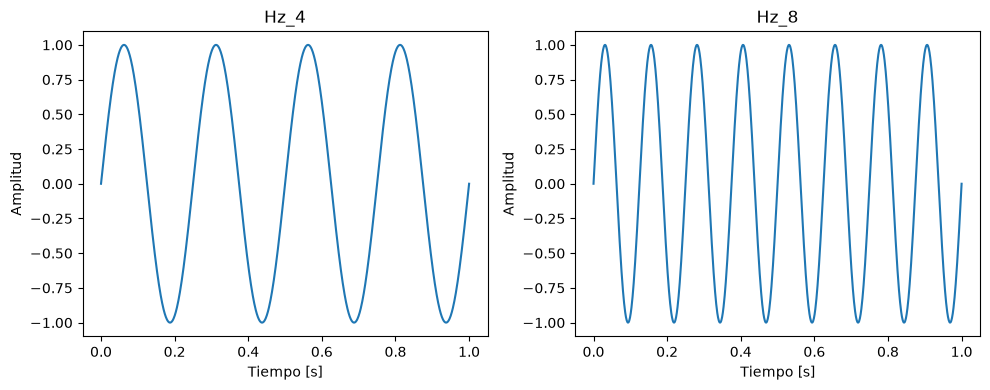

In [8]:
samp_rate = 1000                                      # Frecuencia de muestreo [Hz]
len_in_sec = 1                                        # Duración [s]
t = np.linspace(0, 1, samp_rate*len_in_sec)           # Vector de tiempo

hz_4 = 1*np.sin(4*2*np.pi*t)                          # Senoide de 4 Hz
hz_8 = hz_4*(2*np.cos(4*2*np.pi*t))                   # = sin(2·2π·4t) -> 8 Hz

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.plot(t, hz_4); plt.title('Hz_4'); plt.xlabel('Tiempo [s]'); plt.ylabel('Amplitud')
plt.subplot(1, 2, 2); plt.plot(t, hz_8); plt.title('Hz_8'); plt.xlabel('Tiempo [s]'); plt.ylabel('Amplitud')
plt.tight_layout(); guardar("fsk_06_duplicar_frecuencia"); plt.show()

## Paso 8 · Modulación de la portadora con el multiplicador
Primeros 500 puntos → bit "0" (multiplicador 1, portadora a `space_freq`); siguientes 500 → bit "1" (multiplicador `2cos`, frecuencia doble).

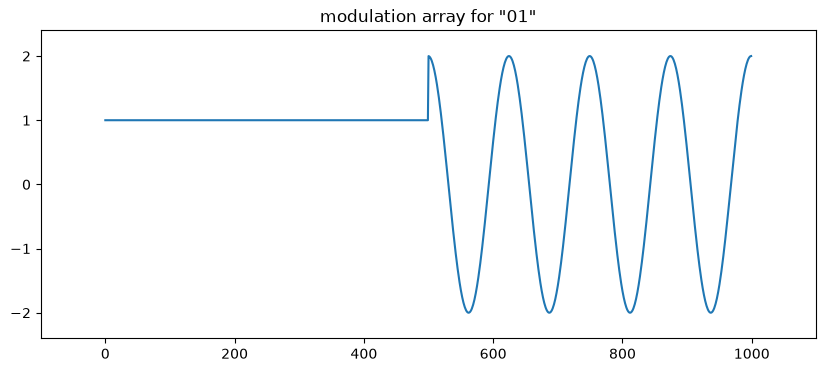

In [9]:
space_freq = 8                                        # Frecuencia para "0" [Hz]
t = np.linspace(0, 1, samp_rate*len_in_sec)
carrier = np.sin(space_freq*2*np.pi*t)                # Portadora
mark_multiplier_array = 2*np.cos(space_freq*2*np.pi*t)  # Multiplicador para "1"

# 500 primeras muestras: "0" (x1); siguientes: "1" (x 2cos)
modulation_array = np.array([1]*500 + [i for i in mark_multiplier_array[500:]])
setup_graph(title='modulation array for "01"', fig_size=(10, 4))
plt.plot(modulation_array); plt.margins(0.1); guardar("fsk_07_modulation_array"); plt.show()

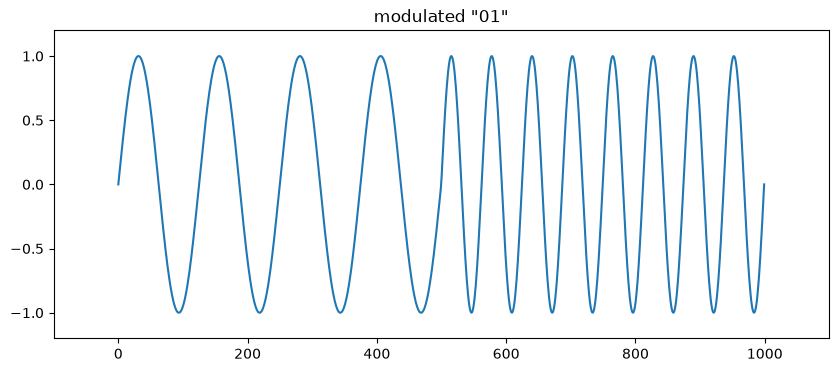

In [10]:
setup_graph(title='modulated "01"', fig_size=(10, 4))
plt.plot(carrier*modulation_array)                    # Portadora x arreglo de modulación = FSK
plt.margins(0.1); guardar("fsk_08_modulated_01"); plt.show()

## Paso 9 · FSK por concatenación de tonos
> **[CORRECCIÓN]** En la guía `t = linspace(0, .5, samp_rate*len_in_sec)` genera 1000 muestras en 0.5 s (fs efectiva 2000 Hz) y cada tono dura 0.5 s, así que el resultado dura 1 s con 2000 muestras. Aquí se usa `samp_rate*0.5 = 500` muestras por bit para que `samp_rate` sea realmente 1000 Hz.

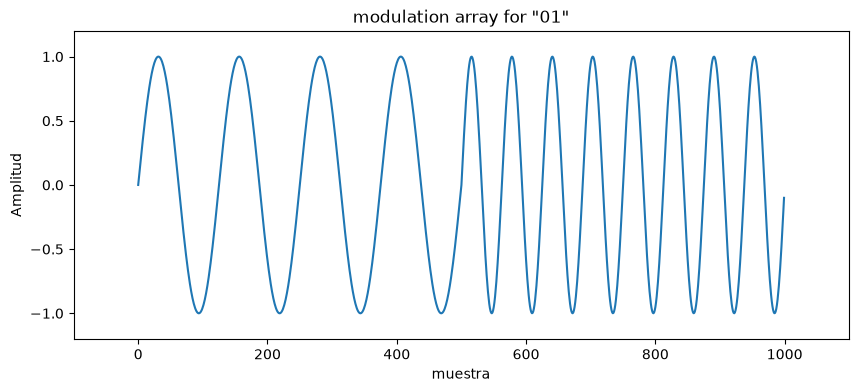

In [11]:
samp_rate = 1000
space_freq = 8    # Hz, bit "0" (space)
mark_freq = 16    # Hz, bit "1" (mark)
t = np.linspace(0, 0.5, int(samp_rate*0.5), endpoint=False)  # 0.5 s por bit, fs = 1000 Hz

space = np.sin(space_freq*2*np.pi*t)                  # Tono del "0"
mark = np.sin(mark_freq*2*np.pi*t)                    # Tono del "1"
modulated_01 = np.append(space, mark)                 # Secuencia "01"

setup_graph(title='modulation array for "01"', x_label='muestra', y_label='Amplitud', fig_size=(10, 4))
plt.plot(modulated_01); plt.margins(0.1); guardar("fsk_09_concatenado_01"); plt.show()

## Paso 10 · Modulador BFSK general
> **[CORRECCIÓN]** La guía llama `baud` a lo que es la *duración del bit en segundos* y pasa `samples_per_bit` como `float` a `np.linspace` (falla en NumPy reciente). Aquí `baud` es baudios [símbolos/s] y se calcula `samples_per_bit = int(fs/baud)`. Con `baud=1` se reproduce exactamente el ejemplo de la guía.

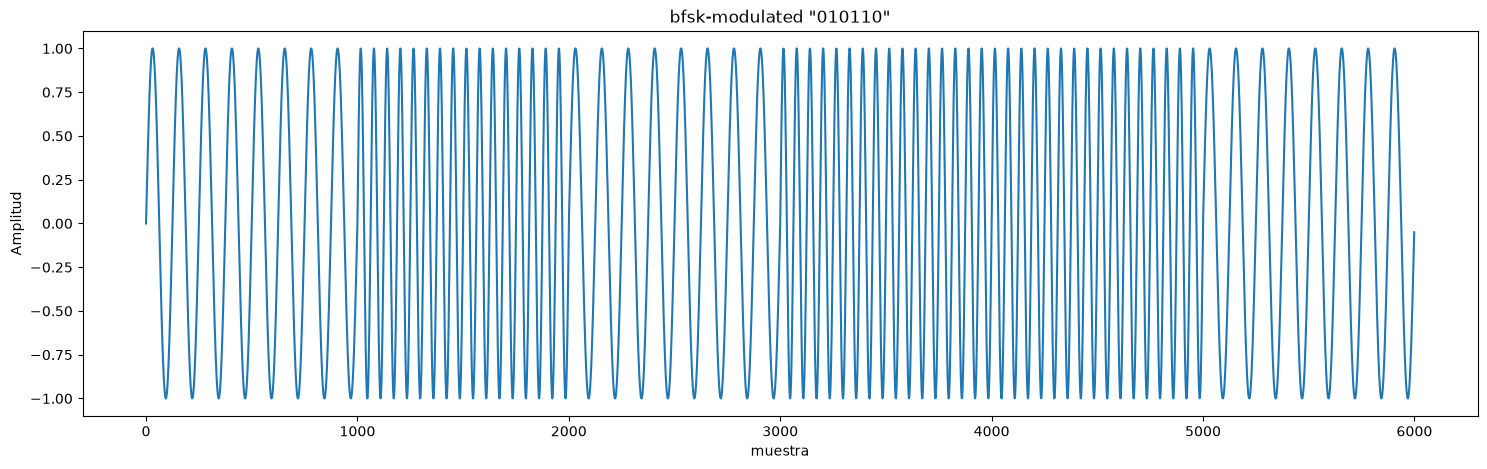

In [12]:
def bfsk_modulate(bit_array, space_freq, mark_freq, baud, sample_rate):
    """Modulador BFSK por concatenación de tonos.
    bit_array: secuencia de bits ('010110' o lista) · baud: bits/s · sample_rate: Hz"""
    seconds_per_bit = 1.0/baud                              # Duración de cada bit [s]
    samples_per_bit = int(round(sample_rate*seconds_per_bit))  # Muestras por bit (entero)
    t = np.arange(samples_per_bit)/sample_rate              # Vector de tiempo de un bit
    space = np.sin(space_freq*2*np.pi*t)                    # Tono para "0"
    mark = np.sin(mark_freq*2*np.pi*t)                      # Tono para "1"
    partes = []                                             # (evita np.append en bucle: O(n^2))
    for bit in bit_array:
        if int(bit) == 0:
            partes.append(space)
        elif int(bit) == 1:
            partes.append(mark)
    return np.concatenate(partes)

test = '010110'                                             # Secuencia de prueba
sig_010110 = bfsk_modulate(test, 8, 16, 1, 1000)

setup_graph(title='bfsk-modulated "010110"', x_label='muestra', y_label='Amplitud', fig_size=(18, 5))
plt.plot(sig_010110); guardar("fsk_10_bfsk_010110"); plt.show()

## Extra · De la simulación al laboratorio (SDR)
Parámetros del experimento real y exportación del mensaje a **.wav** (la guía recomienda convertir el archivo a formato wav).
El mensaje de texto se pasa a bits ASCII y se modula; así se tiene la misma señal en Python y en GNU Radio.

bits: 01000011010011110100010101001100


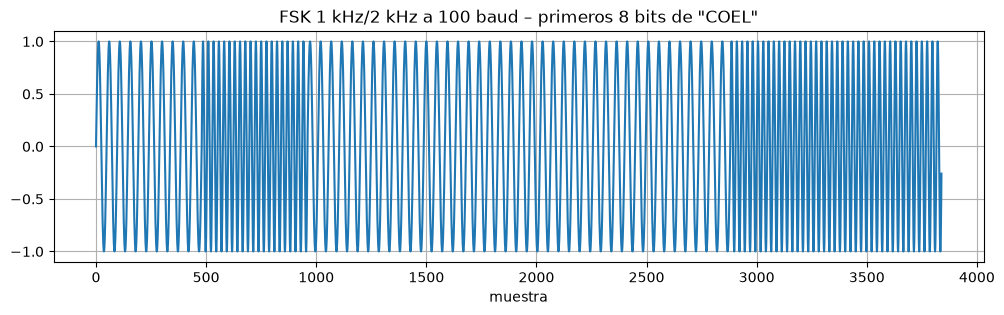

escrito: ../data/mensaje_fsk.wav


In [13]:
mensaje = "COEL"                                             # Mensaje alfanumérico del laboratorio
bits = ''.join(f"{ord(c):08b}" for c in mensaje)             # ASCII -> bits
print("bits:", bits)

fs_audio = 48000                                             # Muestreo de audio
baud = 100                                                   # 100 bit/s -> visible en el osciloscopio
sig = bfsk_modulate(bits, space_freq=1000, mark_freq=2000, baud=baud, sample_rate=fs_audio)

plt.figure(figsize=(12, 3)); plt.plot(sig[:fs_audio//baud*8]); plt.title(f'FSK 1 kHz/2 kHz a {baud} baud – primeros 8 bits de "{mensaje}"')
plt.xlabel("muestra"); plt.grid(True); guardar("fsk_11_mensaje_audio"); plt.show()

# Escritura del .wav (16 bits, mono)
ruta = "../data/mensaje_fsk.wav" if os.path.isdir("../data") else "mensaje_fsk.wav"
with wave.open(ruta, "wb") as w:
    w.setnchannels(1); w.setsampwidth(2); w.setframerate(fs_audio)
    w.writeframes((sig*0.8*32767).astype(np.int16).tobytes())
print("escrito:", ruta)